In [1]:
import pandas as pd
import os

In [2]:
# Define the directory containing CSV files
csv_dir = '../result/test/sctab/scVI-classification-evals-fig2/'

# Define expected columns
columns = ['accuracy', 'precision', 'recall', 'micro_f1', 'macro_f1', 'seed', 'dataset', 'ARtype', 'latent_dim', 'Atlas_cell_count']

# Initialize an empty list to store DataFrames
df_list = []

# Loop over all CSV files in the directory
for file in os.listdir(csv_dir):
    if file.endswith(".csv"):
        file_path = os.path.join(csv_dir, file)
        df_temp = pd.read_csv(file_path, usecols=columns)  # Load only relevant columns
        df_list.append(df_temp)  # Store DataFrame in the list

# Concatenate all DataFrames into one
df = pd.concat(df_list, ignore_index=True) if df_list else pd.DataFrame(columns=columns)


In [3]:
# remove repeted rows
df = df.drop_duplicates()
df.head()

,accuracy,precision,recall,micro_f1,macro_f1,seed,dataset,ARtype,latent_dim,Atlas_cell_count
0,0.454000,0.539048,0.377227,0.454000,0.404164,44,Neurons,F,64,1000
1,0.623760,0.591754,0.481083,0.623760,0.503387,42,Kidney,F,64,0
2,0.676193,0.611642,0.537941,0.676193,0.554870,45,Kidney,F,64,10000
3,0.691129,0.559464,0.461091,0.691129,0.486980,42,Heart,F,64,0
4,0.675012,0.622031,0.543139,0.675012,0.563591,43,Kidney,F,64,10000


In [4]:
assert df[df['ARtype'] == 'T'].shape[0] == df[df['ARtype'] == 'F'].shape[0]
# assert if the number of rows for each seed is the same
assert df[df['seed'] == 42].shape[0] \
    == df[df['seed'] == 43].shape[0] \
    == df[df['seed'] == 44].shape[0] \
    == df[df['seed'] == 45].shape[0] \
    == df[df['seed'] == 46].shape[0] 

In [5]:
df.columns = ['Accuracy', 'Precision', 'Recall', 'Micro F1 Score', 'Macro F1 Score', 'seed', 'dataset', 'ARtype', 'latent_dim', 'Atlas_cell_count']

In [6]:
import pandas as pd

# Define metrics and target columns
metrics = ['Accuracy', 'Precision', 'Recall', 'Micro F1 Score', 'Macro F1 Score']
columns = ['dataset', 'metric', 'value', 'ARtype', 'Atlas_cell_count', 'seed']
plot_df_list = []

# Loop through each row in df
for index, row in df.iterrows():
    for metric in metrics:
        tmp_df = pd.DataFrame([[row['dataset'], metric, row[metric], row['ARtype'], row['Atlas_cell_count'], row['seed']]], 
                              columns=columns)
        plot_df_list.append(tmp_df)

# Concatenate all DataFrames
plot_df = pd.concat(plot_df_list, ignore_index=True) if plot_df_list else pd.DataFrame(columns=columns)


In [7]:
plot_df = plot_df.sort_values(by='Atlas_cell_count')
plot_df.head()

,dataset,metric,value,ARtype,Atlas_cell_count,seed
1044,Heart,Macro F1 Score,0.547637,T,0,46
1043,Heart,Micro F1 Score,0.738137,T,0,46
1042,Heart,Recall,0.512181,T,0,46
1041,Heart,Precision,0.738233,T,0,46
1040,Heart,Accuracy,0.738137,T,0,46


In [8]:
plot_df.tail()

,dataset,metric,value,ARtype,Atlas_cell_count,seed
317,Kidney,Recall,0.782350,T,50000,45
318,Kidney,Micro F1 Score,0.873642,T,50000,45
1025,Neurons,Accuracy,0.895000,F,50000,43
207,Heart,Recall,0.700595,F,50000,45
206,Heart,Precision,0.834822,F,50000,45


In [9]:
# change ARtype to AR and Naive
plot_df['ARtype'] = plot_df['ARtype'].replace({'T': 'AR', 'F': 'Standard'})

In [10]:
# write a piece of code that for each dataset, metric and Atlas_cell_count, it calculated the p-value between AR and Naive using a two-sided paired t-test (pairs = same seed)
from scipy import stats
results = []
for dataset in plot_df['dataset'].unique():
    for metric in plot_df['metric'].unique():
        for atlas_cell_count in plot_df['Atlas_cell_count'].unique():
            ar_values = plot_df[(plot_df['dataset'] == dataset) & 
                                (plot_df['metric'] == metric) & 
                                (plot_df['Atlas_cell_count'] == atlas_cell_count) & 
                                (plot_df['ARtype'] == 'AR')].set_index('seed')['value']
            naive_values = plot_df[(plot_df['dataset'] == dataset) & 
                                   (plot_df['metric'] == metric) & 
                                   (plot_df['Atlas_cell_count'] == atlas_cell_count) & 
                                   (plot_df['ARtype'] == 'Standard')].set_index('seed')['value']
            if len(ar_values) > 1 and len(naive_values) > 1:
                assert set(ar_values.index) == set(naive_values.index)
                t_stat, p_value = stats.ttest_rel(ar_values, naive_values.loc[ar_values.index], alternative='two-sided')
                results.append([dataset, metric, atlas_cell_count, p_value])
            else:
                results.append([dataset, metric, atlas_cell_count, None])

In [11]:
# Create a DataFrame from the results
pval_df = pd.DataFrame(results, columns=['dataset', 'metric', 'Atlas_cell_count', 'p_value'])


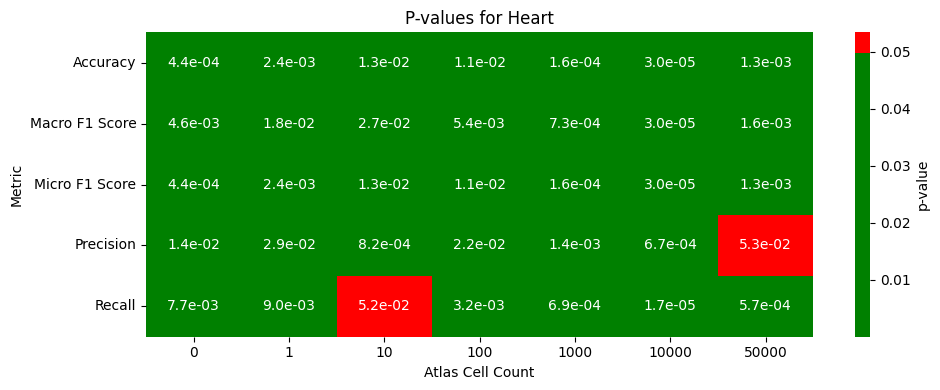

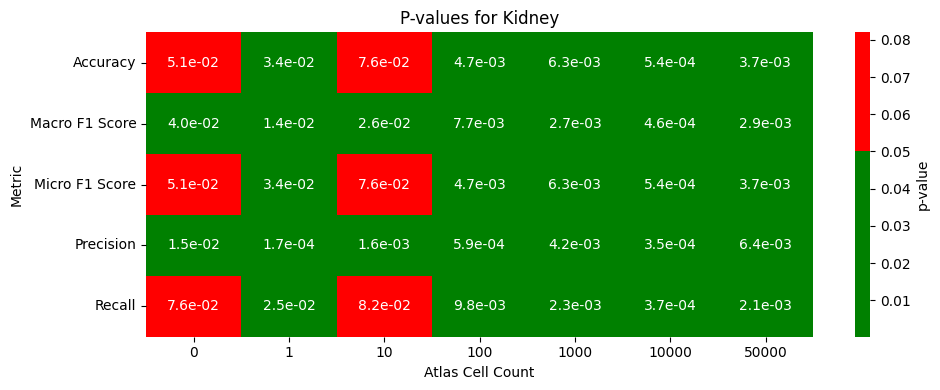

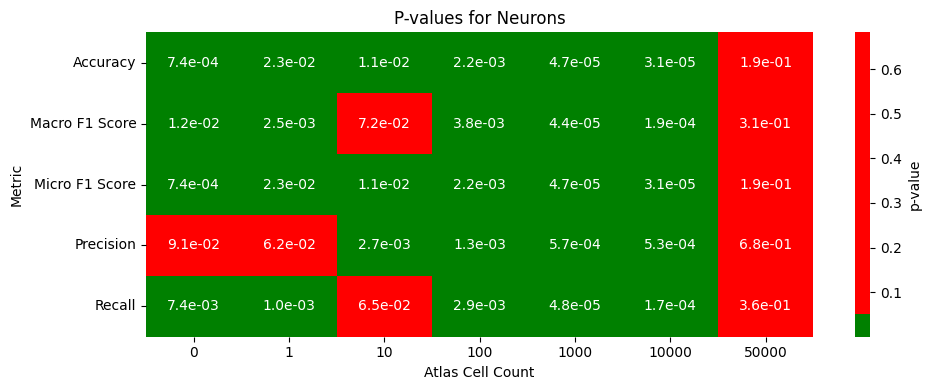

In [12]:
# convert results to a dataframe
results_df = pd.DataFrame(results)
results_df.columns = ['dataset', 'metric', 'Atlas_cell_count', 'p_value']

# plot results_df as a heatmap using seaborn for each dataset separately, with metric on the y-axis, Atlas_cell_count on the x-axis, and p-value < 0.05 light green and >= 0.05 light red, with annotated p-values in scientific notation
import seaborn as sns
import matplotlib.pyplot as plt

for dataset in results_df['dataset'].unique():
    pivot_df = results_df[results_df['dataset'] == dataset].pivot(index='metric', columns='Atlas_cell_count', values='p_value')
    plt.figure(figsize=(10, 4))
    sns.heatmap(pivot_df, annot=True, fmt=".1e", cmap=sns.color_palette(["green", "red"]), center=0.05, cbar_kws={'label': 'p-value'})
    plt.title(f'P-values for {dataset}')
    plt.ylabel('Metric')
    plt.xlabel('Atlas Cell Count')
    plt.tight_layout()
    plt.show()

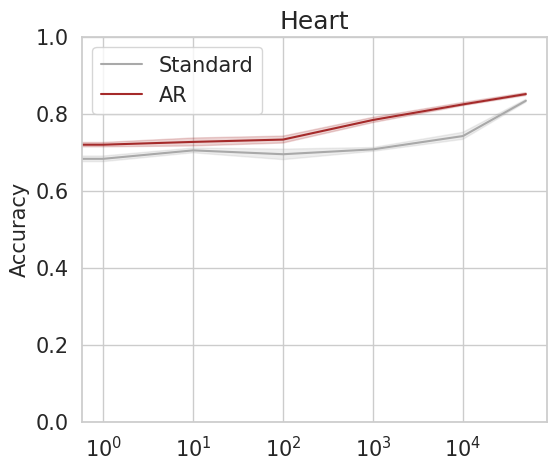

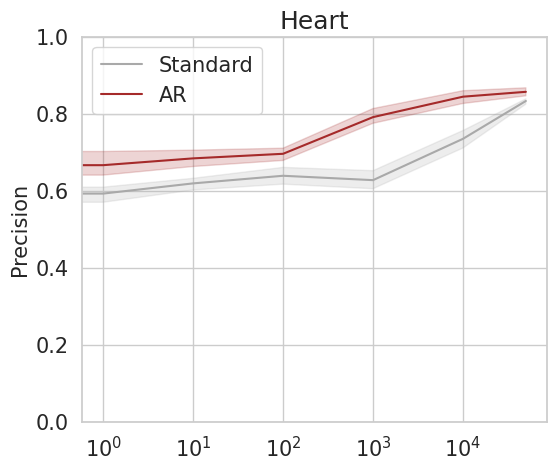

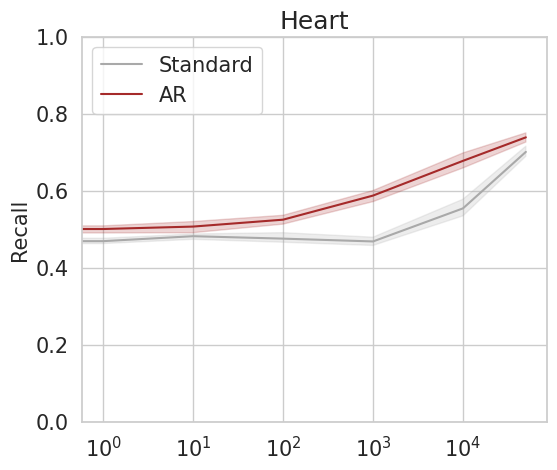

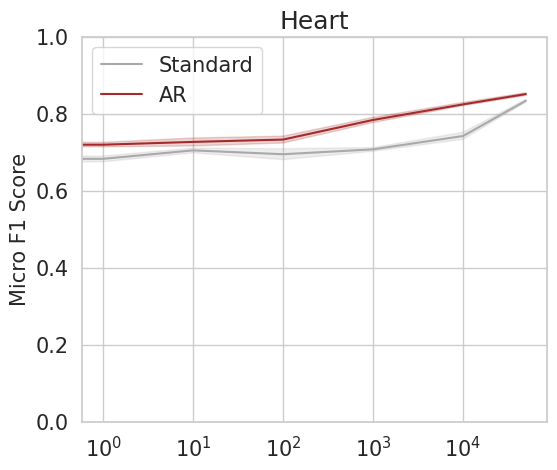

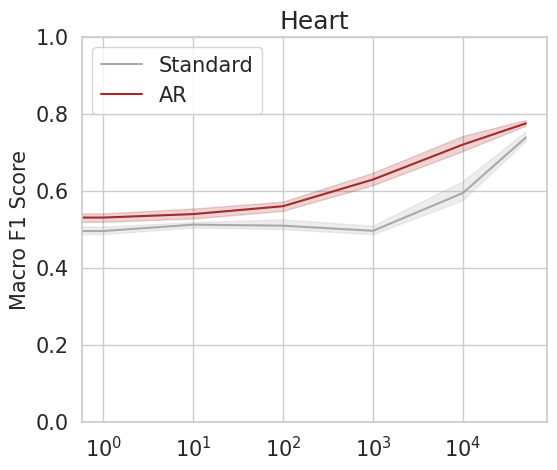

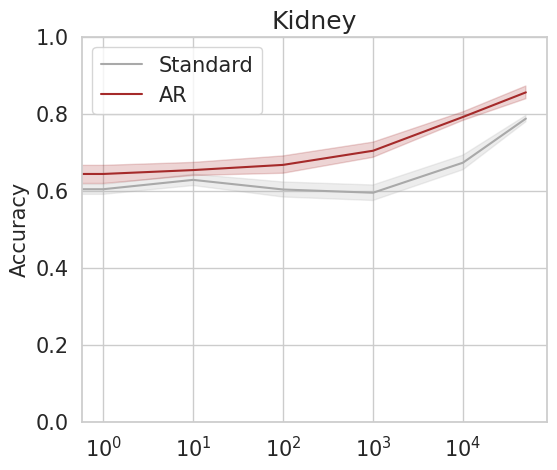

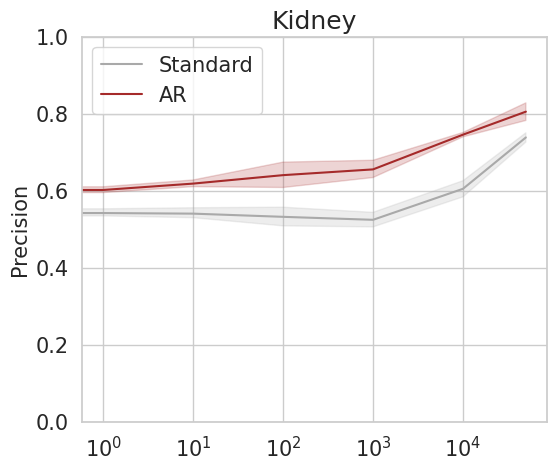

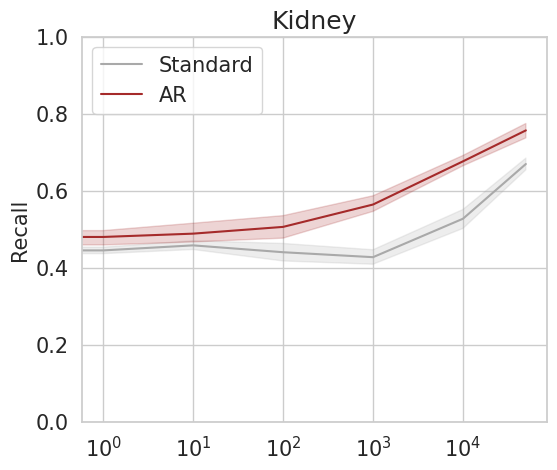

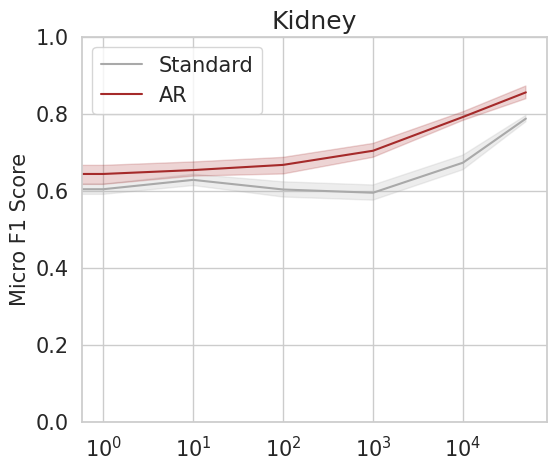

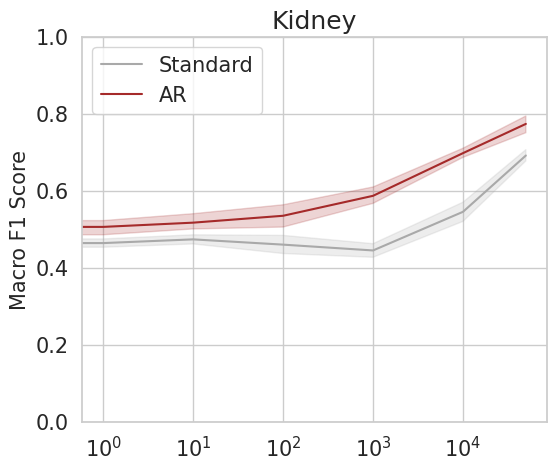

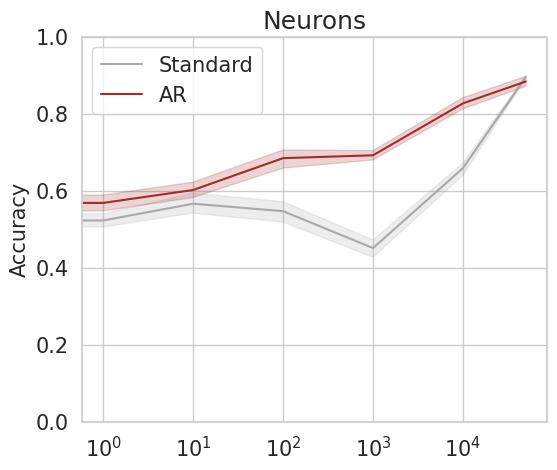

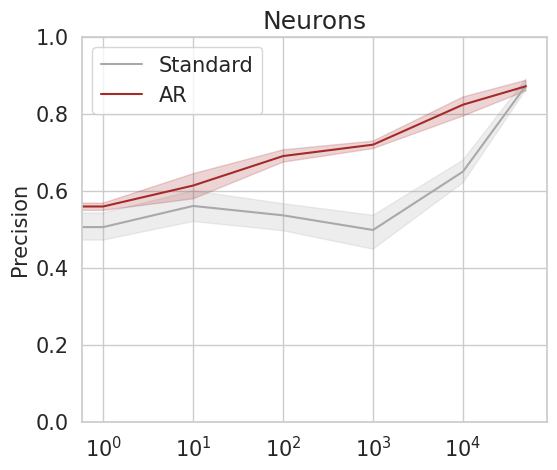

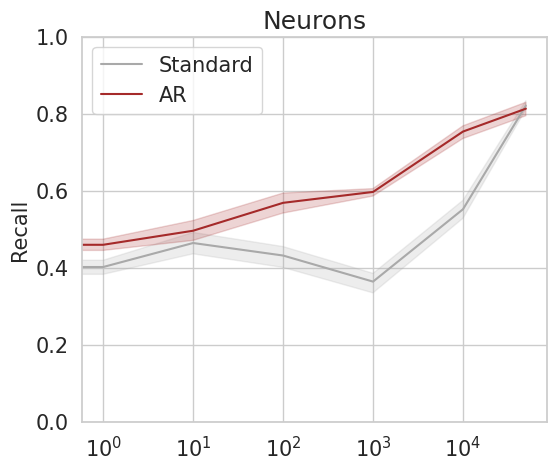

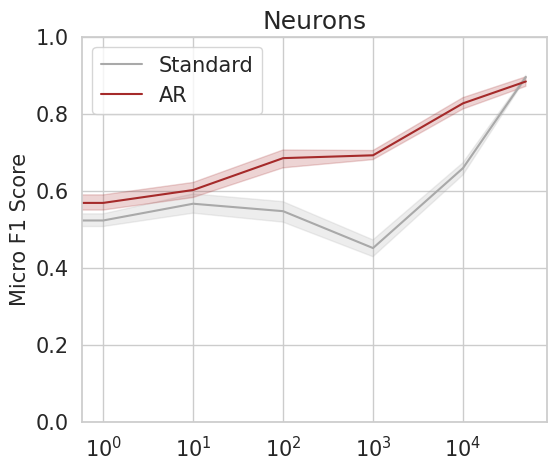

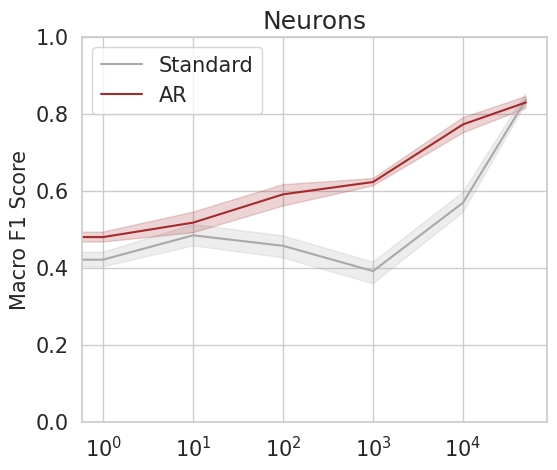

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
os.makedirs('../result/test/sctab/scvi_plots', exist_ok=True)
sns.set_theme(style="whitegrid")
# plot a group barplot for each dataset with metric in x-axis and value in y-axis, hue=AR_Type
palette = {'Standard':"darkgray",
           'AR':"brown"}
for dataset in plot_df['dataset'].unique():
    
    # loop through each metric
    for i, metric in enumerate(metrics):
        # create a new plot
        fig, axs = plt.subplots(1, 1, figsize=(6, 5))
        sns.set_theme(style="whitegrid")
        g = sns.lineplot(data=plot_df[(plot_df['dataset'] == dataset) & (plot_df['metric'] == metric)], 
                         x="Atlas_cell_count", y="value", hue="ARtype", palette=palette,
                         hue_order=['Standard', 'AR'])
        # set x and y labels
        g.set_xlabel('')
        g.set_ylabel(metric, fontsize=15)
        # set the title of the plot
        g.set_title(dataset.capitalize(), fontsize=18)
        # set the font size of the x and y ticks
        g.tick_params(axis='both', which='major', labelsize=15)
        g.tick_params(axis='both', which='minor', labelsize=15)
        g.legend(loc='upper left', fontsize=15)
        g.set(ylim=(0, 1))
        g.set_xscale("log", base=10)
        # save the plot with high resolution
        plt.savefig(f'../result/test/sctab/scvi_plots/{dataset}_{metric}.png', dpi=600,
                    bbox_inches='tight')
        plt.show()


Generate plot for reconstruction error

In [14]:
import pickle
import os
import pandas as pd


df = pd.DataFrame(columns=['dataset', 'metric', 'value', 'ARtype', 'Atlas_cell_count', 'seed'])
dir ='../result/test/sctab/scVI-reconstruction-evals-fig2/'
# loop over all files inside dir and read the pickle files
for file in os.listdir(dir):
    if file.endswith(".pkl") and 'Reconstruction_seed_' in file:
        # print(file)
        
        # extract the dataset name, ARtype, seed and Atlas_cell_count from the file name
        ARtype = file.split('_')[4]
        seed = file.split('_')[2]
        Atlas_cell_count = file.split('_')[11]
        print('ARtype:', ARtype)
        print('seed:', seed)
        print('Atlas_cell_count:', Atlas_cell_count)
    
        # Open the pickle file in read-binary mode
        with open(dir+file, "rb") as f:
            data = pickle.load(f)
            print(list(data.keys()))
            dict_keys = list(data.keys())
            for key in dict_keys:
                test_df = data[key]
                print(test_df.columns)
                mean_r2 = test_df['r2'].mean()
                mean_corr = test_df['correlation'].mean()
                df.loc[len(df)] = [key, 'correlation', mean_corr, ARtype, Atlas_cell_count, seed]
                df.loc[len(df)] = [key, 'r2', mean_r2, ARtype, Atlas_cell_count, seed]


ARtype: F
seed: 46
Atlas_cell_count: 50000
['scTab_Heart_reconstruction', 'scTab_Kidney_reconstruction', 'Neurons_reconstruction']
Index(['correlation', 'r2', 'cell_type'], dtype='object')
Index(['correlation', 'r2', 'cell_type'], dtype='object')
Index(['correlation', 'r2', 'supercluster_term'], dtype='object')
ARtype: T
seed: 46
Atlas_cell_count: 10
['scTab_Heart_reconstruction', 'scTab_Kidney_reconstruction', 'Neurons_reconstruction']
Index(['correlation', 'r2', 'cell_type'], dtype='object')
Index(['correlation', 'r2', 'cell_type'], dtype='object')
Index(['correlation', 'r2', 'supercluster_term'], dtype='object')
ARtype: T
seed: 46
Atlas_cell_count: 1000
['scTab_Heart_reconstruction', 'scTab_Kidney_reconstruction', 'Neurons_reconstruction']
Index(['correlation', 'r2', 'cell_type'], dtype='object')
Index(['correlation', 'r2', 'cell_type'], dtype='object')
Index(['correlation', 'r2', 'supercluster_term'], dtype='object')
ARtype: T
seed: 44
Atlas_cell_count: 10000
['scTab_Heart_reconstr

In [15]:
# include only rows with seed in [42, 43, 44, 45, 46]
df = df[df['seed'].isin(['42', '43', '44', '45', '46'])]
print(df[df['ARtype'] == 'T'].shape[0])
print(df[df['ARtype'] == 'F'].shape[0])

print('df[df[seed] == 42].shape[0]:', df[df['seed'] == '42'].shape[0])
print('df[df[seed] == 43].shape[0]:', df[df['seed'] == '43'].shape[0])
print('df[df[seed] == 44].shape[0]:', df[df['seed'] == '44'].shape[0])
print('df[df[seed] == 45].shape[0]:', df[df['seed'] == '45'].shape[0])
print('df[df[seed] == 46].shape[0]:', df[df['seed'] == '46'].shape[0])

# print the number of rows for each Atlas_cell_count
print('Atlas_cell_count:', df['Atlas_cell_count'].unique())
# print the number of rows for each Atlas_cell_count=0,1,10,100,1000,10000,50000
print('Atlas_cell_count=0:', df[df['Atlas_cell_count'] == '0'].shape[0])
print('Atlas_cell_count=1:', df[df['Atlas_cell_count'] == '1'].shape[0])
print('Atlas_cell_count=10:', df[df['Atlas_cell_count'] == '10'].shape[0])
print('Atlas_cell_count=100:', df[df['Atlas_cell_count'] == '100'].shape[0])
print('Atlas_cell_count=1000:', df[df['Atlas_cell_count'] == '1000'].shape[0])
print('Atlas_cell_count=10000:', df[df['Atlas_cell_count'] == '10000'].shape[0])
print('Atlas_cell_count=50000:', df[df['Atlas_cell_count'] == '50000'].shape[0])


assert df[df['ARtype'] == 'T'].shape[0] == df[df['ARtype'] == 'F'].shape[0]
# assert if the number of rows for each seed is the same
assert df[df['seed'] == '42'].shape[0] \
    == df[df['seed'] == '43'].shape[0] \
    == df[df['seed'] == '44'].shape[0] \
    == df[df['seed'] == '45'].shape[0] \
    == df[df['seed'] == '46'].shape[0] 
    
df.shape

210
210
df[df[seed] == 42].shape[0]: 84
df[df[seed] == 43].shape[0]: 84
df[df[seed] == 44].shape[0]: 84
df[df[seed] == 45].shape[0]: 84
df[df[seed] == 46].shape[0]: 84
Atlas_cell_count: ['50000' '10' '1000' '10000' '100' '1' '0']
Atlas_cell_count=0: 60
Atlas_cell_count=1: 60
Atlas_cell_count=10: 60
Atlas_cell_count=100: 60
Atlas_cell_count=1000: 60
Atlas_cell_count=10000: 60
Atlas_cell_count=50000: 60


(420, 6)

In [16]:
# if 'heart' in df.dataset.lower, change it to 'Heart', if 'kidney' in df.dataset.lower, change it to 'Kidney'
df['dataset'] = df['dataset'].apply(lambda x: 'Heart' if 'heart' in x.lower() else x)
df['dataset'] = df['dataset'].apply(lambda x: 'Kidney' if 'kidney' in x.lower() else x)
df['dataset'] = df['dataset'].apply(lambda x: 'Neurons' if x=='Neurons_reconstruction' else x)

In [17]:
# replace ARtype with Standard
df['ARtype'] = df['ARtype'].apply(lambda x: 'Standard' if x == 'F' else 'AR')

In [18]:
# write a piece of code that for each dataset, metric and Atlas_cell_count, it calculated the p-value between AR and Naive using a two-sided paired t-test (pairs = same seed)
from scipy import stats
results = []

for dataset in df['dataset'].unique():
    for metric in df['metric'].unique():
        for atlas_cell_count in df['Atlas_cell_count'].unique():
            ar_values = df[(df['dataset'] == dataset) & 
                                (df['metric'] == metric) & 
                                (df['Atlas_cell_count'] == atlas_cell_count) & 
                                (df['ARtype'] == 'AR')].set_index('seed')['value']
            naive_values = df[(df['dataset'] == dataset) & 
                                   (df['metric'] == metric) & 
                                   (df['Atlas_cell_count'] == atlas_cell_count) & 
                                   (df['ARtype'] == 'Standard')].set_index('seed')['value']
            if len(ar_values) > 1 and len(naive_values) > 1:
                assert set(ar_values.index) == set(naive_values.index)
                t_stat, p_value = stats.ttest_rel(ar_values, naive_values.loc[ar_values.index], alternative='two-sided')
                results.append([dataset, metric, atlas_cell_count, p_value])
            else:
                results.append([dataset, metric, atlas_cell_count, None])

In [19]:
# convert results to a dataframe
results_df = pd.DataFrame(results)
results_df.columns = ['dataset', 'metric', 'Atlas_cell_count', 'p_value']
print('shape of results_df:', results_df.shape)
results_df

shape of results_df: (42, 4)


,dataset,metric,Atlas_cell_count,p_value
0,Heart,correlation,50000,6.039994e-05
1,Heart,correlation,10,2.556351e-03
2,Heart,correlation,1000,4.316970e-05
3,Heart,correlation,10000,8.625646e-07
4,Heart,correlation,100,4.771218e-06
5,Heart,correlation,1,1.752978e-04
6,Heart,correlation,0,1.097912e-05
7,Heart,r2,50000,5.263863e-05
8,Heart,r2,10,3.560516e-03
9,Heart,r2,1000,1.156196e-04


In [20]:
# LaTeX p-value tables, one per dataset (classification metrics + reconstruction correlation).
# Bold = P < 0.05; dagger = P < 0.05 and AR has the higher mean.
TABLE_METRICS = ['Accuracy', 'Macro F1 Score', 'Micro F1 Score', 'Precision', 'Recall', 'Correlation']
GROUP_COLS = ['dataset', 'metric', 'Atlas_cell_count']

table_values = pd.concat([plot_df, df[df['metric'] == 'correlation'].assign(metric='Correlation')])
table_values = table_values.astype({'Atlas_cell_count': int, 'value': float})
table_means = table_values.pivot_table(index=GROUP_COLS, columns='ARtype', values='value', aggfunc='mean')
table_pvalues = pd.concat([pval_df, results_df[results_df['metric'] == 'correlation'].assign(metric='Correlation')])
table_pvalues = table_pvalues.astype({'Atlas_cell_count': int, 'p_value': float}).set_index(GROUP_COLS)['p_value']
table_pvalues = table_pvalues[table_pvalues.index.get_level_values('metric').isin(TABLE_METRICS)]
assert set(table_pvalues.index) <= set(table_means.index)


def format_pval_latex(val, ar_outperforms=False):
    if pd.isna(val):
        return ''
    formatted = f'{val:.2e}'
    if val < 0.05:
        mark = r'$^{\dagger}$' if ar_outperforms else ''
        return rf'\textbf{{{formatted}}}{mark}'
    return rf'\cellcolor{{white}}{{{formatted}}}'


def latex_pvalue_table(dataset):
    atlas_cols = sorted(table_pvalues.index.get_level_values('Atlas_cell_count').unique())
    caption = (
        f'The p-values for two-sided seed-matched paired t-tests on evaluation metrics '
        f'for AR and standard scVI tested on the {dataset.lower()} dataset. '
        f'Bold indicates statistical significance as determined by $P<0.05$. '
        f'A dagger ($^{{\\dagger}}$) marks the significant values where AR has the higher mean. '
        f'Results are based on five replicates.'
    )
    lines = [
        r'\begin{table*}[ht]',
        rf'\caption{{{caption}}}',
        r'\centering',
        rf'\label{{tab:pvalues_{dataset}}}',
        rf"\begin{{tabular}}{{{'l' + 'r' * len(atlas_cols)}}}",
        r'\toprule',
        r'\# Atlas Cells & ' + ' & '.join(str(c) for c in atlas_cols) + r' \\',
        r'\midrule',
    ]
    for metric in TABLE_METRICS:
        if metric == 'Correlation':
            lines.append(r'\midrule')
        row_cells = [metric]
        for atlas in atlas_cols:
            means = table_means.loc[(dataset, metric, atlas)]
            row_cells.append(format_pval_latex(table_pvalues.loc[(dataset, metric, atlas)],
                                               ar_outperforms=means['AR'] > means['Standard']))
        lines.append(' & '.join(row_cells) + r' \\')
    lines.extend([r'\bottomrule', r'\end{tabular}', r'\end{table*}'])
    return '\n'.join(lines)


for dataset in table_pvalues.index.get_level_values('dataset').unique():
    print(latex_pvalue_table(dataset))
    print()


\begin{table*}[ht]
\caption{The p-values for two-sided seed-matched paired t-tests on evaluation metrics for AR and standard scVI tested on the heart dataset. Bold indicates statistical significance as determined by $P<0.05$. A dagger ($^{\dagger}$) marks the significant values where AR has the higher mean. Results are based on five replicates.}
\centering
\label{tab:pvalues_Heart}
\begin{tabular}{lrrrrrrr}
\toprule
\# Atlas Cells & 0 & 1 & 10 & 100 & 1000 & 10000 & 50000 \\
\midrule
Accuracy & \textbf{4.39e-04}$^{\dagger}$ & \textbf{2.44e-03}$^{\dagger}$ & \textbf{1.33e-02}$^{\dagger}$ & \textbf{1.08e-02}$^{\dagger}$ & \textbf{1.59e-04}$^{\dagger}$ & \textbf{2.98e-05}$^{\dagger}$ & \textbf{1.34e-03}$^{\dagger}$ \\
Macro F1 Score & \textbf{4.59e-03}$^{\dagger}$ & \textbf{1.81e-02}$^{\dagger}$ & \textbf{2.70e-02}$^{\dagger}$ & \textbf{5.36e-03}$^{\dagger}$ & \textbf{7.29e-04}$^{\dagger}$ & \textbf{2.99e-05}$^{\dagger}$ & \textbf{1.61e-03}$^{\dagger}$ \\
Micro F1 Score & \textbf{4.39e-04

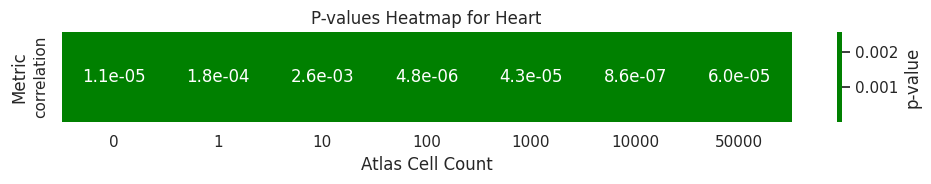

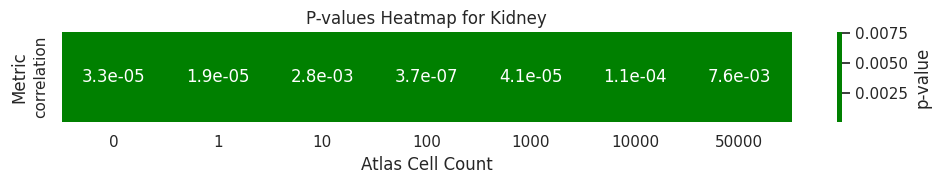

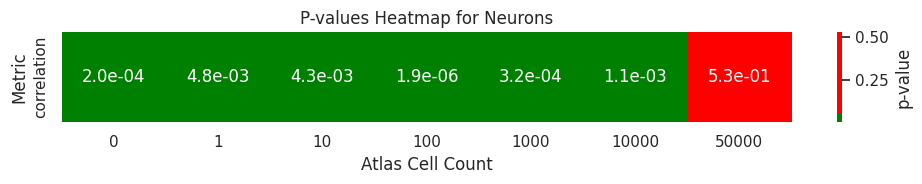

In [21]:

# plot heatmap of p-values for each dataset, where x axis is Atlas_cell_count, y axis is metric, and color is green if p-value < 0.05 else red
import seaborn as sns
import matplotlib.pyplot as plt
results_df = results_df[results_df['metric'].isin(['correlation'])]
for dataset in results_df['dataset'].unique():
    pivot_df = results_df[results_df['dataset'] == dataset].pivot(index='metric', columns='Atlas_cell_count', values='p_value')
    plt.figure(figsize=(10, 2))
    sns.heatmap(pivot_df, annot=True, fmt=".1e", cmap=sns.color_palette(["green", "red"]), center=0.05, cbar_kws={'label': 'p-value'})
    plt.title(f'P-values Heatmap for {dataset}')
    plt.xlabel('Atlas Cell Count')
    plt.ylabel('Metric')
    plt.axhline(y=-0.5, color='black', linewidth=2)  # Horizontal line at the top
    plt.axvline(x=-0.5, color='black', linewidth=2)  # Vertical line at the left
    plt.tight_layout()
    plt.show()


<cell>:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(g.get_xticklabels(), horizontalalignment='right')


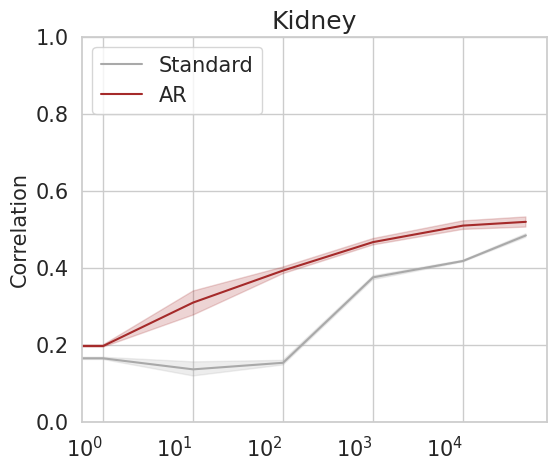

<cell>:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(g.get_xticklabels(), horizontalalignment='right')


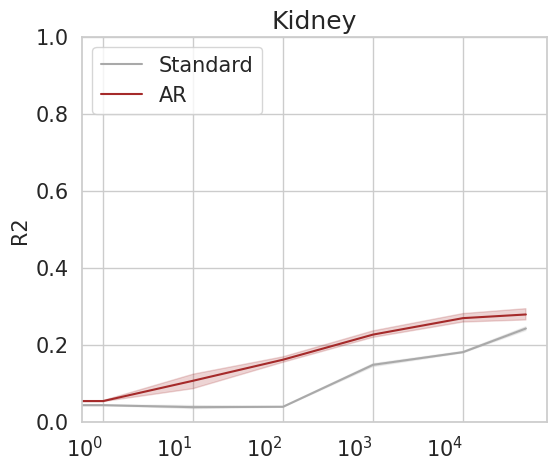

<cell>:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(g.get_xticklabels(), horizontalalignment='right')


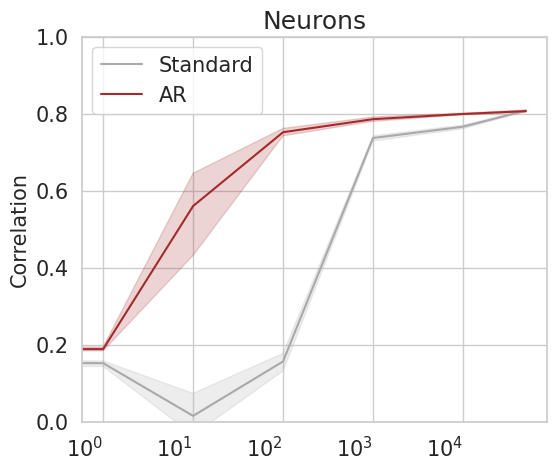

<cell>:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(g.get_xticklabels(), horizontalalignment='right')


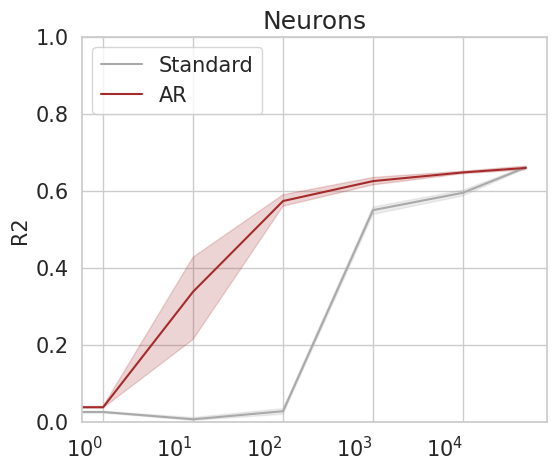

<cell>:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(g.get_xticklabels(), horizontalalignment='right')


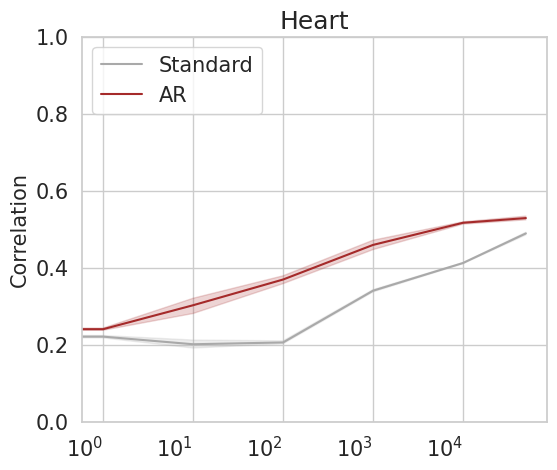

<cell>:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.set_xticklabels(g.get_xticklabels(), horizontalalignment='right')


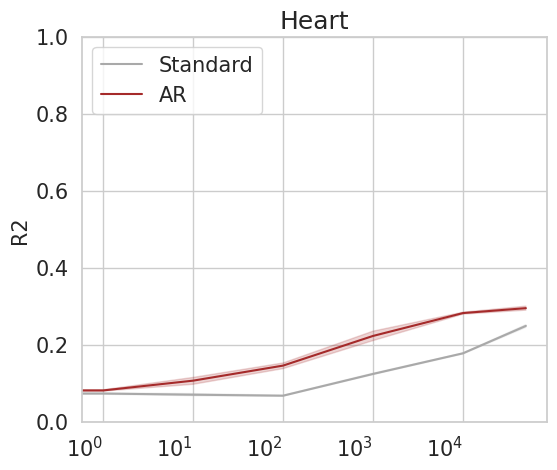

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs('../result/test/sctab/scvi_plots', exist_ok=True)
# plot group barplot with Atlas_cell_count in x-axis, value in y-axis, hue=ARtype
# convert Atlas_cell_count to log scale

# convert the Atlas_cell_count label into int format
df['Atlas_cell_count'] = df['Atlas_cell_count'].astype(int)
# sort based on Atlas_cell_count
df = df.sort_values(by='Atlas_cell_count')

# plot a group barplot for each dataset with metric in x-axis and value in y-axis, hue=AR_Type
palette = {'Standard':"darkgray",
           'AR':"brown"}

for dataset in df['dataset'].unique():
    # loop through each metric
    for i, metric in enumerate(['correlation', 'r2']):
        fig, axs = plt.subplots(1, 1, figsize=(6, 5))
        sns.set_theme(style="whitegrid")
        g = sns.lineplot(data=df[(df['dataset'] == dataset) & (df['metric'] == metric)], 
                         x="Atlas_cell_count", y="value", hue="ARtype", palette=palette,
                         hue_order=['Standard', 'AR'])
        # set x and y labels
        g.set_xticklabels(g.get_xticklabels(), horizontalalignment='right')
        g.set_xlabel('')
        g.set_ylabel(metric.capitalize(), fontsize=15)
        g.set_title(dataset.capitalize(), fontsize=18)
        g.tick_params(axis='both', which='major', labelsize=15)
        g.tick_params(axis='both', which='minor', labelsize=15)
        g.set_xscale("log", base=10)
        g.legend(loc='upper left', fontsize=15)
        g.set(ylim=(0,1))
        
        # save the plot with high resolution
        plt.savefig(f'../result/test/sctab/scvi_plots/{dataset}_{metric}.png', dpi=600,
                    bbox_inches='tight')
        plt.show()
        
        